Dataset shape: (61069, 21)
  class  cap-diameter cap-shape cap-surface cap-color does-bruise-or-bleed  \
0     p         15.26         x           g         o                    f   
1     p         16.60         x           g         o                    f   
2     p         14.07         x           g         o                    f   
3     p         14.17         f           h         e                    f   
4     p         14.64         x           h         o                    f   

  gill-attachment gill-spacing gill-color  stem-height  ...  stem-root  \
0               e          NaN          w        16.95  ...          s   
1               e          NaN          w        17.99  ...          s   
2               e          NaN          w        17.80  ...          s   
3               e          NaN          w        15.77  ...          s   
4               e          NaN          w        16.53  ...          s   

  stem-surface stem-color veil-type veil-color has-ring rin

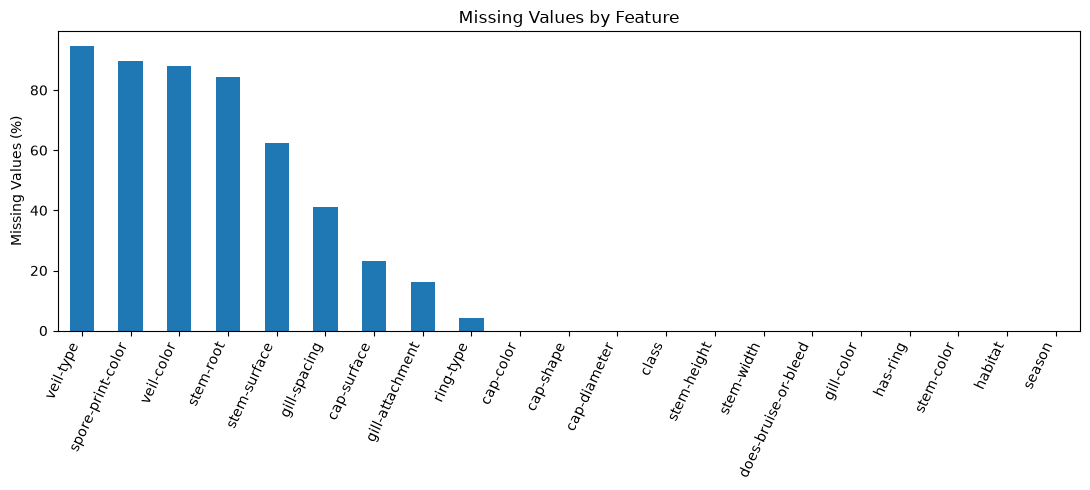

Duplicates: 146
       cap-diameter   stem-height    stem-width
count  60923.000000  60923.000000  60923.000000
mean       6.741957      6.597202     12.178484
std        5.268435      3.358757     10.030361
min        0.380000      0.000000      0.000000
25%        3.490000      4.650000      5.250000
50%        5.880000      5.960000     10.220000
75%        8.550000      7.750000     16.580000
max       62.340000     33.920000    103.910000
class
p    55.384666
e    44.615334
Name: proportion, dtype: float64
Dropped columns: ['stem-root', 'veil-type', 'veil-color', 'spore-print-color']


/tmp/ipykernel_7246/712252201.py:58: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(


class                   0
cap-diameter            0
cap-shape               0
cap-surface             0
cap-color               0
does-bruise-or-bleed    0
gill-attachment         0
gill-spacing            0
gill-color              0
stem-height             0
stem-width              0
stem-surface            0
stem-color              0
has-ring                0
ring-type               0
habitat                 0
season                  0
dtype: int64


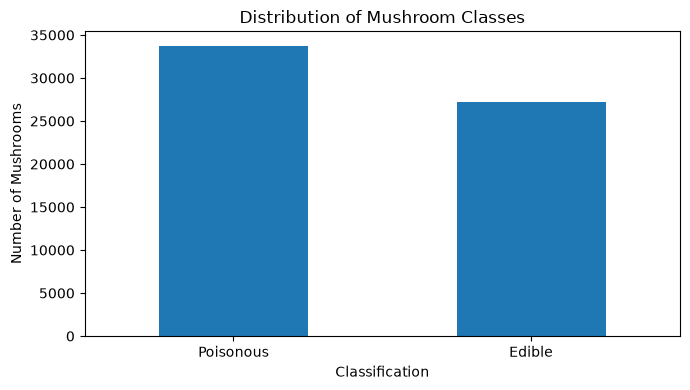

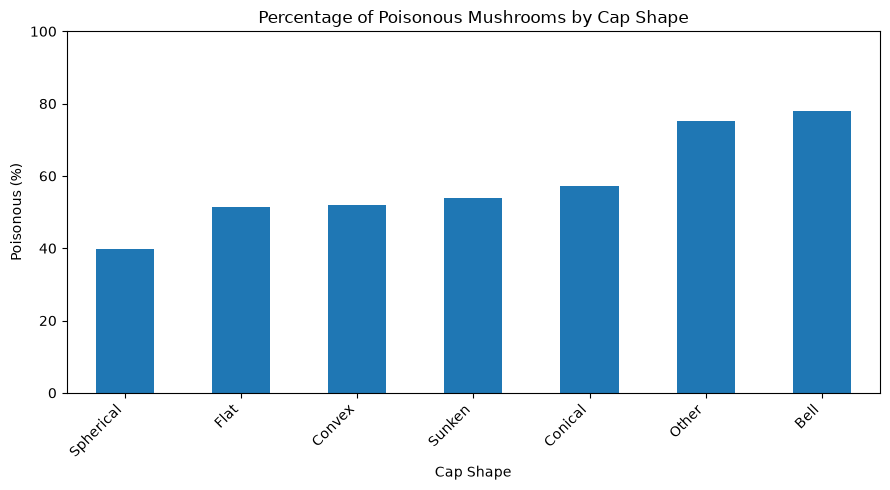

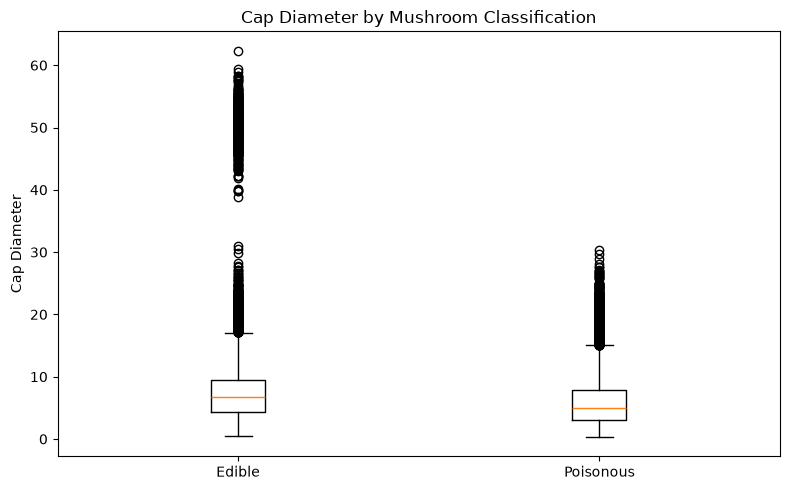

/tmp/ipykernel_7246/712252201.py:158: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  c for c in train_df.select_dtypes(include="object").columns


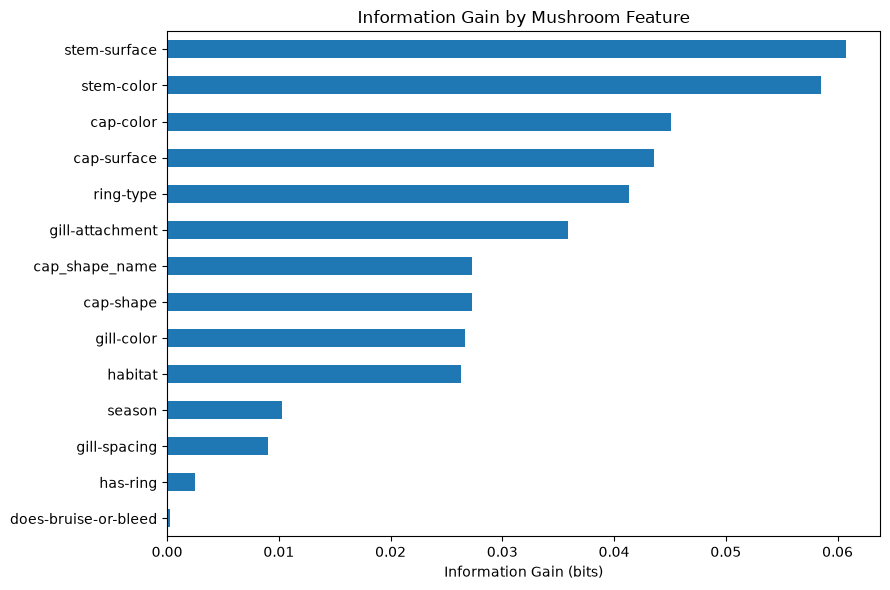

stem-surface            0.060762
stem-color              0.058537
cap-color               0.045086
cap-surface             0.043601
ring-type               0.041352
gill-attachment         0.035838
cap-shape               0.027279
cap_shape_name          0.027279
gill-color              0.026700
habitat                 0.026282
season                  0.010276
gill-spacing            0.009052
has-ring                0.002490
does-bruise-or-bleed    0.000267
dtype: float64


/tmp/ipykernel_7246/712252201.py:212: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


Accuracy: 0.7256462864177267
              precision    recall  f1-score   support

   Poisonous       0.84      0.62      0.72      6749
      Edible       0.65      0.85      0.73      5436

    accuracy                           0.73     12185
   macro avg       0.74      0.74      0.73     12185
weighted avg       0.75      0.73      0.72     12185



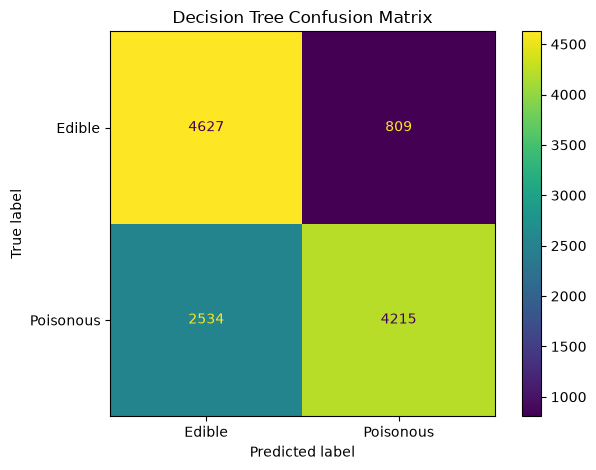

In [4]:

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load the dataset
df = pd.read_csv("../data/secondary_data.csv", sep=";")

# Step 2: Inspect the data
print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

# Step 3: Missing values
missing = df.isnull().sum()
missing_pct = df.isnull().mean() * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_pct
}).sort_values("Missing %", ascending=False)

print(missing_summary)

# Visualise missing percentages
missing_summary["Missing %"].plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Missing Values by Feature")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

# Step 4: Check duplicates
print("Duplicates:", df.duplicated().sum())

# Remove exact duplicates
df = df.drop_duplicates().copy()

# Step 5: Check numerical variables
print(df.describe())

# Step 6: Check class distribution
print(df["class"].value_counts(normalize=True) * 100)


#------------------------------------------------------
# Make a working copy
df_clean = df.copy()

# Remove columns with over 80% missing values
missing_pct = df_clean.isnull().mean()
columns_to_drop = missing_pct[missing_pct > 0.80].index.tolist()

df_clean = df_clean.drop(columns=columns_to_drop)
print("Dropped columns:", columns_to_drop)

# Fill remaining missing categorical values
categorical_cols = df_clean.select_dtypes(
    include="object"
).columns.drop("class")

df_clean[categorical_cols] = (
    df_clean[categorical_cols].fillna("Missing")
)

# Check remaining missing values
print(df_clean.isnull().sum())

# Save the prepared dataset
df_clean.to_csv("../data/mushrooms_cleaned.csv", index=False)



#Graph 1 — Edible vs poisonous mushrooms
import matplotlib.pyplot as plt

counts = df_clean["class"].value_counts()
counts = counts.rename({"e": "Edible", "p": "Poisonous"})

counts.plot(kind="bar", figsize=(7, 4))
plt.title("Distribution of Mushroom Classes")
plt.ylabel("Number of Mushrooms")
plt.xlabel("Classification")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


#Graph 2 — Cap shape vs toxicity


cap_shape_labels = {
    "b": "Bell",
    "c": "Conical",
    "x": "Convex",
    "f": "Flat",
    "s": "Sunken",
    "p": "Spherical",
    "o": "Other"
}

df_clean["cap_shape_name"] = (
    df_clean["cap-shape"].map(cap_shape_labels)
)

cap_rates = (
    df_clean.groupby("cap_shape_name")["class"]
    .apply(lambda x: (x == "p").mean() * 100)
    .sort_values()
)

cap_rates.plot(kind="bar", figsize=(9, 5))
plt.title("Percentage of Poisonous Mushrooms by Cap Shape")
plt.xlabel("Cap Shape")
plt.ylabel("Poisonous (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


#Graph 3 — Cap diameter vs toxicity

edible = df_clean.loc[
    df_clean["class"] == "e", "cap-diameter"
]

poisonous = df_clean.loc[
    df_clean["class"] == "p", "cap-diameter"
]

plt.figure(figsize=(8, 5))
plt.boxplot([edible, poisonous],
            tick_labels=["Edible", "Poisonous"])
plt.title("Cap Diameter by Mushroom Classification")
plt.ylabel("Cap Diameter")
plt.tight_layout()
plt.show()



#-----------------------------------------------------
#Information gain

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score

train_df, test_df = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=42,
    stratify=df_clean["class"]
)

# Information gain for categorical variables
categorical_features = [
    c for c in train_df.select_dtypes(include="object").columns
    if c != "class"
]

ig_scores = {}

for feature in categorical_features:
    ig_scores[feature] = (
        mutual_info_score(
            train_df[feature], train_df["class"]
        ) / np.log(2)
    )

ig = pd.Series(ig_scores).sort_values(ascending=False)

# Plot information gain
ig.sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Information Gain by Mushroom Feature")
plt.xlabel("Information Gain (bits)")
plt.tight_layout()
plt.show()

print(ig)

#------------------------------------------------------
#Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Step 1: Separate features and target
# Exclude any previously created duplicate or target columns
exclude = ["class", "toxicity", "cap_shape_name"]

X_train = train_df.drop(columns=exclude, errors="ignore")
X_test = test_df[X_train.columns]

y_train = train_df["class"]
y_test = test_df["class"]

# Step 2: Identify feature types
numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include="object"
).columns.tolist()

# Step 3: Prepare preprocessing
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

# Step 4: Build the decision tree
tree_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        random_state=42
    ))
])

# Step 5: Train the model
tree_model.fit(X_train, y_train)

# Step 6: Make predictions
y_pred = tree_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(
    y_test, y_pred,
    labels=["p", "e"],
    target_names=["Poisonous", "Edible"]
))


#Confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["e", "p"],
    display_labels=["Edible", "Poisonous"]
)

plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()
